# Modelagem preditiva e avaliação de classificadores (Atividade_Formativa.ipynb)

- **Repositório:** `machine-learning-portfolio`  
- **Tecnologias:** Scikit-Learn  
- **Arquivo Original:** `Atividade_Formativa.ipynb`  

---


In [4]:
# Carregando recursos necessários
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn import datasets
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
import sklearn.model_selection as model_selection
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import xgboost as xgb

from warnings import simplefilter
simplefilter(action='ignore', category=FutureWarning)

In [8]:
import pandas as pd
import numpy as np
# loading attribute names
att=pd.read_csv('glass.csv', index_col=-1, nrows=0).columns.tolist()
print(att)
# loading the data
dataset = np.loadtxt('glass.csv', delimiter=",", skiprows=1)
X = dataset[:,0:9]
y = dataset[:,9]
print(X.shape)


['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe']
(214, 9)


In [17]:
from sklearn.model_selection import GridSearchCV, train_test_split, cross_val_predict
from sklearn.metrics import f1_score
from tabulate import tabulate
import pandas as pd

# Definir os parâmetros para o KNN
parameters = [
  {'n_neighbors': [1, 3, 5, 7, 9, 11, 13, 15, 17, 19],  # Maior variedade de vizinhos
   'weights': ['uniform', 'distance'],  # Pesos uniformes ou por distância
   'metric': ['euclidean', 'manhattan', 'chebyshev', 'minkowski'],  # Diferentes métricas de distância
   'p': [1, 2, 3, 4]}  # Diferentes valores de 'p' para a métrica Minkowski (p=1 é Manhattan, p=2 é Euclidean, p>=3 são métricas mais customizadas)
]


# Definir o número de folds
folds = 5

# Instanciar o modelo KNN
model = KNeighborsClassifier()

# Separando uma parte para base de validação (20%)
X, X_val, y, y_val = train_test_split(X, y, train_size=0.8, random_state=42)

# GridSearch para customizar os parâmetros sobre base de validação
gs = GridSearchCV(model, parameters, scoring='r2', cv=folds, n_jobs=-1)
gs.fit(X_val, y_val)

# Exibir os resultados da busca em grid
df = gs.cv_results_
print(tabulate(df, headers='keys', tablefmt='psql'))
print("Melhores parâmetros encontrados: ", gs.best_params_)

# Recuperando os melhores parâmetros
model = gs.best_estimator_

# Usando a validação cruzada com 5 folds
T = 5  # número de folds
y_pred = cross_val_predict(model, X, y, cv=T)

# Calcular o F1 score
f1 = f1_score(y, y_pred, average='macro')

# Exibir o F1 score
print("F1 Score com o melhor modelo KNN: ", f1)


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


+-----------------+----------------+-------------------+------------------+----------------+---------------------+-----------+-----------------+---------------------------------------------------------------------------+---------------------+---------------------+---------------------+---------------------+---------------------+-------------------+------------------+-------------------+
|   mean_fit_time |   std_fit_time |   mean_score_time |   std_score_time | param_metric   |   param_n_neighbors |   param_p | param_weights   | params                                                                    |   split0_test_score |   split1_test_score |   split2_test_score |   split3_test_score |   split4_test_score |   mean_test_score |   std_test_score |   rank_test_score |
|-----------------+----------------+-------------------+------------------+----------------+---------------------+-----------+-----------------+---------------------------------------------------------------------------+

Acurácia média: 0.696
Desvio padrão: 0.093
f1: 0.643
Matriz de Confusão


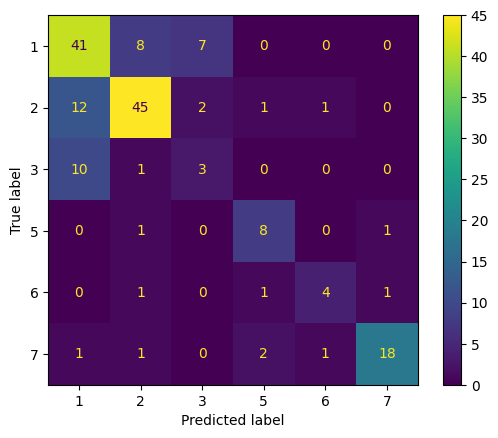

In [37]:
# Instanciando o Bagging
bg = BaggingClassifier(random_state=42)

# Caso queira usar Gridsearch, segue exemplo
# Retirando 20% da base para o GridSearch
X, X_val, y, y_val = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)
# Obs: há mais hiperparâmetros do Bagging que poderiam ser explorados neste caso, segue exemplo abaixo:
bag_param = [{'estimator': [best_knn],'n_estimators': [10, 30], 'max_samples': [0.5, 0.7, 1.0]}]
clf = GridSearchCV(bg, bag_param, scoring = 'accuracy', cv=5)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=[1,2,3,5,6,7])
disp.plot()




/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklea

Acurácia média: 0.704
Desvio padrão: 0.109


/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 3 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/model_selection/_split.py:776: UserWarning: The least populated class in y has only 2 members, which is less than n_splits=5.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklea

f1: 0.528
Matriz de Confusão


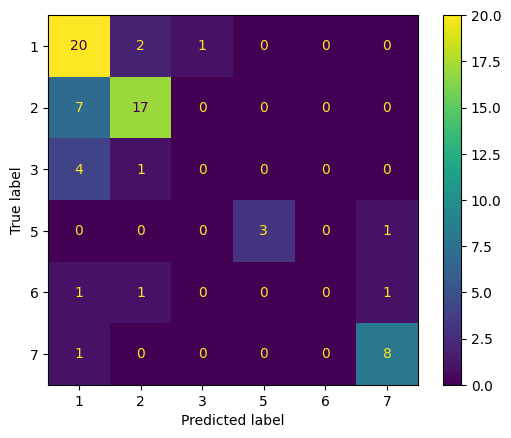

In [41]:
knn = KNeighborsClassifier(metric= 'manhattan', n_neighbors= 1, weights= 'uniform')

# Instanciando o Bagging
bg = BaggingClassifier(random_state=42)

# Caso queira usar Gridsearch, segue exemplo
# Retirando 20% da base para o GridSearch
X, X_val, y, y_val = train_test_split(X,y,test_size=0.2, random_state=42, stratify=y)
# Obs: há mais hiperparâmetros do Bagging que poderiam ser explorados neste caso, segue exemplo abaixo:
bag_param = [{'estimator': [knn],'n_estimators': [10, 30], 'max_samples': [0.5, 0.7, 1.0]}]
clf = GridSearchCV(bg, bag_param, scoring = 'accuracy', cv=5)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=[1,2,3,5,6,7])
disp.plot()




Acurácia média: 0.956
Desvio padrão: 0.017
f1: 0.953
Matriz de Confusão


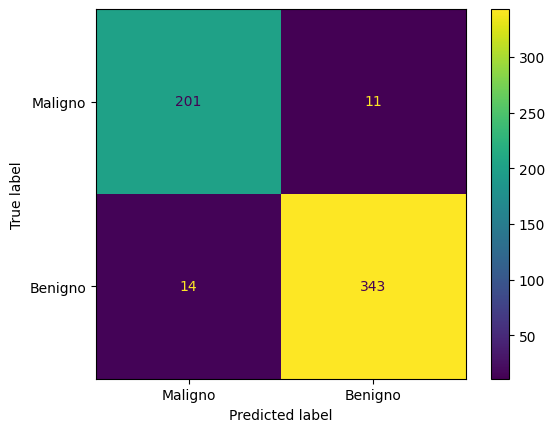

In [ ]:
# Exemplo de outros Algoritmos de ensembles homogêneos (AdaBoost, XGBoost e Random Forest).
# Agora sem uso do GridSearch. Dá para usar GridSearch claro, mas aqui optamos por nao.
# Carregando a base de dados
X,y=load_breast_cancer(return_X_y=True)

# Instanciado a técnica escolhida
# clf = AdaBoostClassifier(n_estimators=100, random_state=42)
xgboost = xgb.XGBClassifier(objective="binary:logistic", random_state=42)
#rf = RandomForestClassifier(n_estimators=100, random_state=42)

# Usando validação cruzada com T=5 folds
result=model_selection.cross_val_score(clf, X, y, cv=5)
print("Acurácia média: %.3f" % result.mean())
print("Desvio padrão: %.3f" % result.std())

# Calculando a predição para cada exempolo de teste
y_pred=model_selection.cross_val_predict(clf, X, y, cv=5)

# Calcular f1 score
f1=f1_score(y, y_pred, average='macro')
print("f1: %.3f" % f1)

print("Matriz de Confusão")
matrix=confusion_matrix(y, y_pred)
#print(matrix)
disp=ConfusionMatrixDisplay(confusion_matrix=matrix,display_labels=['Maligno', 'Benigno'])
disp.plot()



